# Model Evaluation & Interpretation — Telco Customer Churn

This notebook is the **final report** for the modeling pipeline.

## When using Google colab

In [36]:
# Mount Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    print("Google Drive mounted successfully.")
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab environment. Using local directory paths.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully.


In [37]:
if IN_COLAB:
    !pip install -q xgboost "scikit-learn>=1.9.0" pandas pyarrow fastparquet joblib matplotlib seaborn


## 1. Environment Configuration & Path Setup

In [38]:
from pathlib import Path
import json, os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, accuracy_score, balanced_accuracy_score, matthews_corrcoef,
    log_loss, brier_score_loss, confusion_matrix, fbeta_score,
    roc_curve, precision_recall_curve
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

In [39]:
PROJECT_CANDIDATES = [Path("/content/drive/MyDrive/Projects/Week1and2Project"), Path("..")]
PROJECT_ROOT = next(
    (p.resolve() for p in PROJECT_CANDIDATES
     if (p / "DataFrames/X_test.parquet").exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run PreProcessing.ipynb and ML.ipynb first.")

DATAFRAMES_DIR = PROJECT_ROOT / "DataFrames"
ARTIFACTS_DIR = PROJECT_ROOT / "Artifacts"
MODELS_DIR = PROJECT_ROOT / "Models"
FIGURES_DIR = PROJECT_ROOT / "Results"
CV_RESULTS_DIR = os.path.join(FIGURES_DIR, "cv_results")
METRICS_DIR = os.path.join(FIGURES_DIR, "metrics")
FIGURES_DIR.mkdir(exist_ok=True)

In [40]:
TARGET = "Churn"
RANDOM_STATE = 42

In [41]:
X_train = pd.read_parquet(DATAFRAMES_DIR / "X_train.parquet")
X_test = pd.read_parquet(DATAFRAMES_DIR / "X_test.parquet")
y_train = pd.read_parquet(DATAFRAMES_DIR / "y_train.parquet")[TARGET].astype(int)
y_test = pd.read_parquet(DATAFRAMES_DIR / "y_test.parquet")[TARGET].astype(int)

# Filenames as actually saved by ML.ipynb (joblib.dump calls in the RF/SVC/XGBoost cells)
MODEL_FILES = {
    "Random Forest": "rf_final_model.joblib",
    "SVC": "svc_final_model.joblib",
    "XGBoost": "xgboost_final_model.joblib",
}
models = {name: joblib.load(MODELS_DIR / fname) for name, fname in MODEL_FILES.items()}
model_names = list(models)

# ML.ipynb doesn't persist test-set probabilities, so score the held-out set here
test_probabilities = pd.DataFrame(
    {name: model.predict_proba(X_test)[:, 1] for name, model in models.items()},
    index=X_test.index,
)

# Reuse the OOF-selected thresholds ML.ipynb already computed and saved per model
test_results_saved = pd.read_csv(os.path.join(METRICS_DIR, "model_test_results.csv"))
thresholds = dict(zip(test_results_saved["Model"], test_results_saved["Threshold"]))

oof_probabilities = pd.read_parquet(FIGURES_DIR / "oof_probabilities.parquet").drop(columns=[TARGET])

print("Models:", list(models))
print(f"Test size: {len(X_test):,}")
print(f"Test churn rate: {y_test.mean():.2%}")


Models: ['Random Forest', 'SVC', 'XGBoost']
Test size: 1,405
Test churn rate: 26.48%


## 1. What each metric means

**ROC-AUC:** how well the model ranks churners above non-churners. Primary model-comparison metric.

**Average Precision (PR-AUC):** summarizes precision/recall performance and is especially informative when the positive class is uncommon.

**Precision:** among predicted churners, the fraction that really churned.

**Recall:** among actual churners, the fraction detected.

**Specificity:** among non-churners, the fraction correctly identified.

**F1:** harmonic mean of precision and recall.

**F2:** like F1, but gives more weight to recall.

**Balanced Accuracy:** average of recall and specificity.

**MCC:** correlation-style metric that uses all four confusion-matrix cells and behaves well with class imbalance.

**Brier score / Log Loss:** probability-quality metrics. Lower is better.

## 2. Final test-set performance

In [42]:
rows = []
for name, proba_series in test_probabilities.items():
    proba = proba_series.to_numpy()
    threshold = float(thresholds[name])
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Average Precision": average_precision_score(y_test, proba),
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "Specificity": specificity,
        "F1": f1_score(y_test, pred, zero_division=0),
        "F2": fbeta_score(y_test, pred, beta=2, zero_division=0),
        "MCC": matthews_corrcoef(y_test, pred),
        "Brier": brier_score_loss(y_test, proba),
        "Log Loss": log_loss(y_test, proba),
        "Threshold": threshold
    })

results_df = pd.DataFrame(rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
display(results_df.style.format({
    c: "{:.4f}" for c in results_df.columns
    if c not in ["Threshold"]
}).format({"Threshold": "{:.3f}"}))

best_model_name = results_df.index[0]
print(f"\nCurrent champion by held-out ROC-AUC: {best_model_name}")

,ROC-AUC,Average Precision,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,F2,MCC,Brier,Log Loss,Threshold
Model,,,,,,,,,,,,,
XGBoost,0.842620,0.655444,0.762278,0.765230,0.535448,0.771505,0.758955,0.632159,0.708992,0.481817,0.159438,0.475817,0.505
Random Forest,0.840808,0.654470,0.743772,0.762106,0.510274,0.801075,0.723136,0.623431,0.719112,0.469300,0.160259,0.479571,0.470
SVC,0.836546,0.641775,0.752313,0.757594,0.521898,0.768817,0.746370,0.621739,0.702358,0.466021,0.155199,0.467270,0.465



Current champion by held-out ROC-AUC: XGBoost


### How to judge the table

Do **not** look for one universal "good" number.

- ROC-AUC answers whether the model ranks customers well.
- Average Precision checks performance on the churn class.
- Precision/Recall/F1 depend on the selected threshold.
- Brier and Log Loss tell us whether the probabilities themselves are trustworthy.

A difference such as 0.843 vs 0.842 is tiny; it should not be described as a dramatic model improvement without uncertainty analysis.

## 3. ROC curves

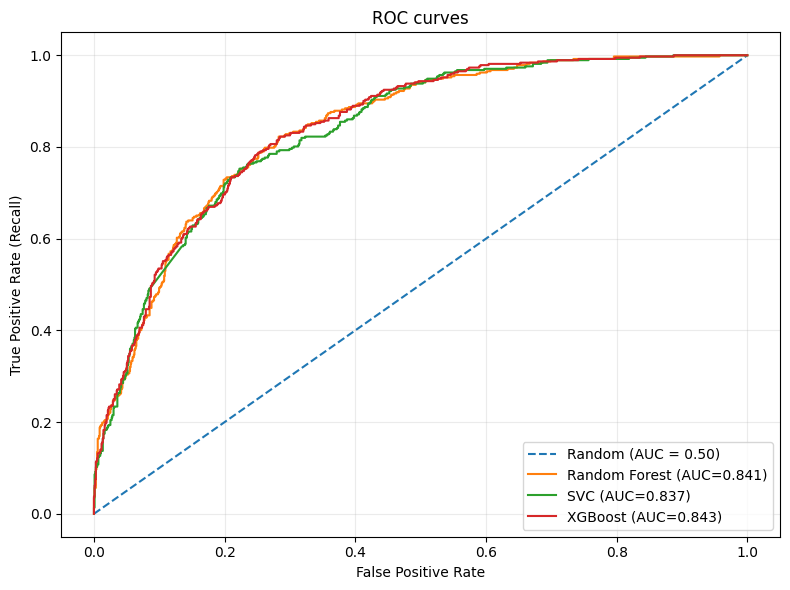

In [43]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot([0, 1], [0, 1], "--", label="Random (AUC = 0.50)")

for name, proba_series in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, proba_series)
    auc = roc_auc_score(y_test, proba_series)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

ax.set_title("ROC curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_roc_curves.png", dpi=250, bbox_inches="tight")
plt.show()

**Purpose:** compare ranking/discrimination. A curve closer to the upper-left is better.

**Important:** ROC-AUC is threshold-independent, so it is appropriate for comparing model quality before deciding how aggressively to classify churn.

## 4. Precision–Recall curves

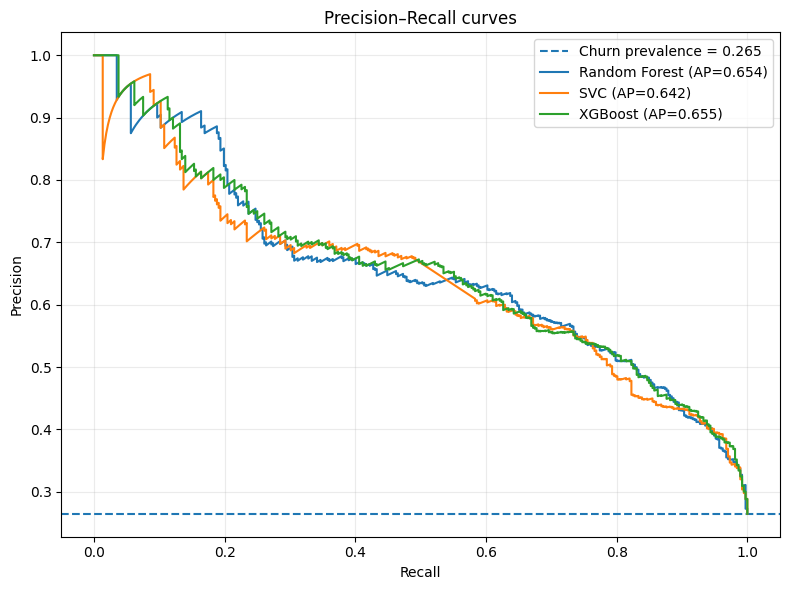

In [44]:
fig, ax = plt.subplots(figsize=(8, 6))
baseline = y_test.mean()
ax.axhline(baseline, linestyle="--", label=f"Churn prevalence = {baseline:.3f}")

for name, proba_series in test_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, proba_series)
    ap = average_precision_score(y_test, proba_series)
    ax.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

ax.set_title("Precision–Recall curves")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_precision_recall_curves.png", dpi=250, bbox_inches="tight")
plt.show()

**Purpose:** show the trade-off between catching churners and generating false alarms.

This is especially useful here because churn is the minority class.

## 5. Confusion matrices at the OOF-selected thresholds

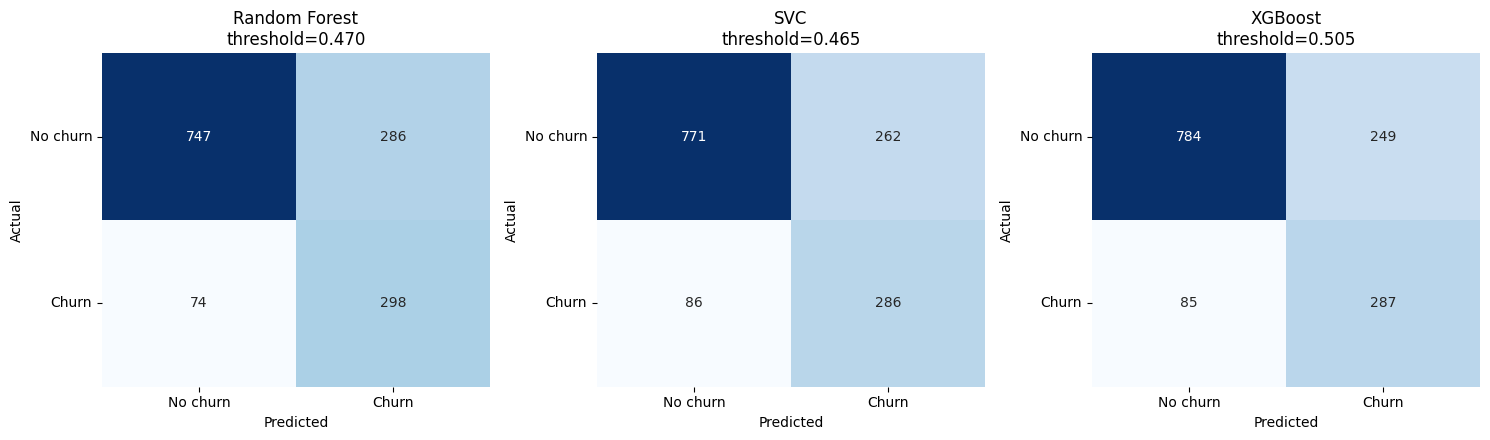

In [45]:
n = len(models)
fig, axes = plt.subplots(1, n, figsize=(5*n, 4.5))
if n == 1:
    axes = [axes]

for ax, name in zip(axes, models):
    proba = test_probabilities[name].to_numpy()
    pred = (proba >= thresholds[name]).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{name}\nthreshold={thresholds[name]:.3f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticklabels(["No churn", "Churn"])
    ax.set_yticklabels(["No churn", "Churn"], rotation=0)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_confusion_matrices.png", dpi=250, bbox_inches="tight")
plt.show()

**Purpose:** turn the abstract metrics into actual error types:

- **TP:** correctly found churners
- **FN:** missed churners
- **FP:** false alarms
- **TN:** correctly identified non-churners

The threshold is not automatically 0.50. It was selected using OOF training predictions.

## 6. Threshold curves

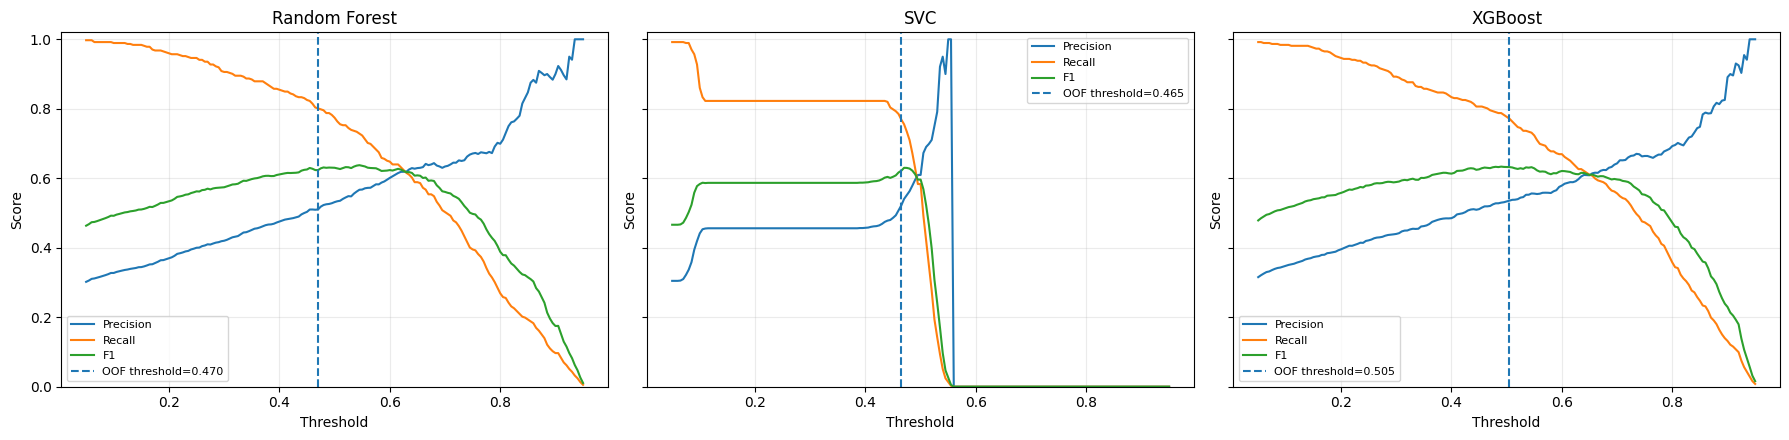

In [46]:
threshold_grid = np.linspace(0.05, 0.95, 181)

fig, axes = plt.subplots(1, len(models), figsize=(6*len(models), 4.5), sharey=True)
if len(models) == 1:
    axes = [axes]

for ax, name in zip(axes, models):
    proba = test_probabilities[name].to_numpy()
    precision_values, recall_values, f1_values = [], [], []

    for t in threshold_grid:
        pred = (proba >= t).astype(int)
        precision_values.append(precision_score(y_test, pred, zero_division=0))
        recall_values.append(recall_score(y_test, pred, zero_division=0))
        f1_values.append(f1_score(y_test, pred, zero_division=0))

    ax.plot(threshold_grid, precision_values, label="Precision")
    ax.plot(threshold_grid, recall_values, label="Recall")
    ax.plot(threshold_grid, f1_values, label="F1")
    ax.axvline(thresholds[name], linestyle="--", label=f"OOF threshold={thresholds[name]:.3f}")
    ax.set_title(name)
    ax.set_xlabel("Threshold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_threshold_curves.png", dpi=250, bbox_inches="tight")
plt.show()

**Purpose:** teach an important distinction:

The model outputs a probability. The threshold converts that probability into a class label.

Changing the threshold changes precision and recall without retraining the model.

The dashed line is the threshold selected from training OOF predictions, so the final test set is not used to choose it.

## 7. Calibration

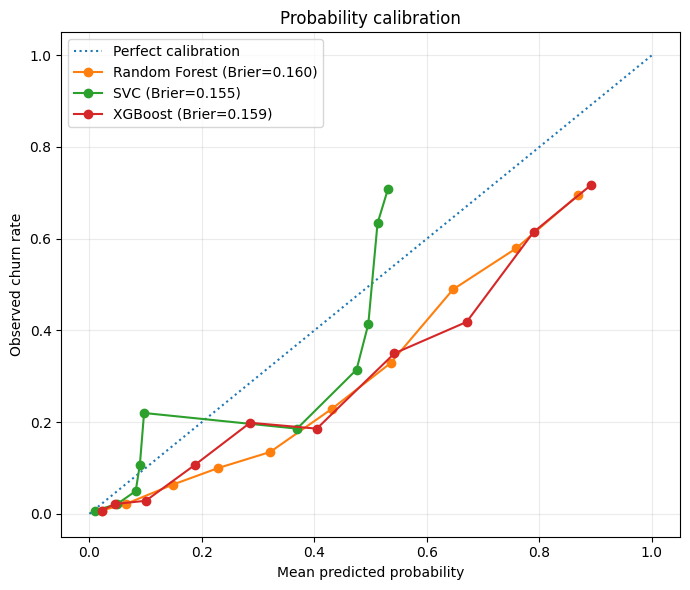

In [47]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], ":", label="Perfect calibration")

for name, proba_series in test_probabilities.items():
    prob_true, prob_pred = calibration_curve(
        y_test, proba_series, n_bins=10, strategy="quantile"
    )
    brier = brier_score_loss(y_test, proba_series)
    ax.plot(prob_pred, prob_true, "o-", label=f"{name} (Brier={brier:.3f})")

ax.set_title("Probability calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed churn rate")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_calibration.png", dpi=250, bbox_inches="tight")
plt.show()

**Purpose:** check whether probabilities can be interpreted as risks.

Example: if customers in a predicted 0.70-risk group actually churn about 70% of the time, the model is well calibrated in that region.

Calibration is different from discrimination: a model can rank customers well while producing poorly calibrated probabilities.

## 8. Generalization: cross-validation vs test

,CV ROC-AUC,Test ROC-AUC
Model,,
Random Forest,NaN,0.840808
SVC,NaN,0.836546
XGBoost,NaN,0.842620
random_forest,0.848186,NaN
svm,0.844598,NaN
xgboost,0.850374,NaN


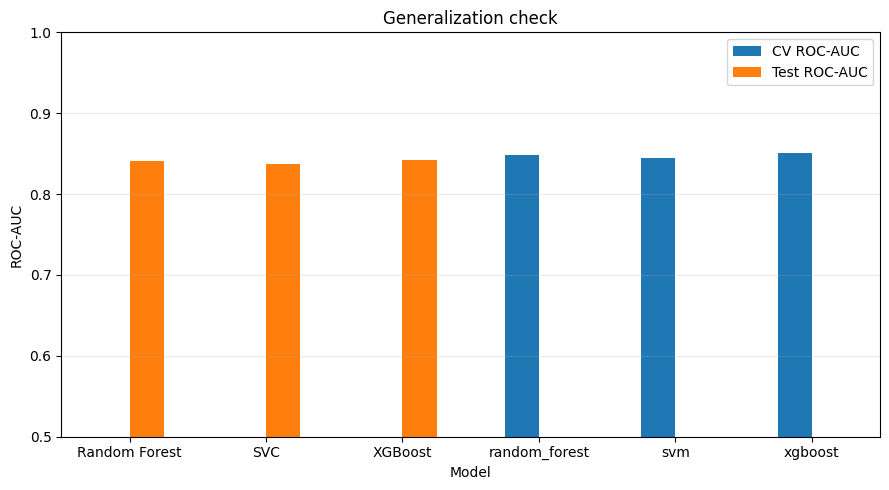

In [48]:
cv_df = pd.read_json(os.path.join(CV_RESULTS_DIR, "model_cv_results.json")).set_index("Model")
cv_df.index = cv_df.index.map({"random_forest": "Random Forest", "svm": "SVC", "xgboost": "XGBoost"})

comparison = pd.DataFrame({
    "CV ROC-AUC": cv_df["CV ROC-AUC"],
    "Test ROC-AUC": results_df["ROC-AUC"],
})
display(comparison)

ax = comparison.plot(kind="bar", figsize=(9, 5))
ax.set_title("Generalization check")
ax.set_ylabel("ROC-AUC")
ax.set_ylim(0.5, 1.0)
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_generalization.png", dpi=250, bbox_inches="tight")
plt.show()


**Purpose:** detect obvious overfitting.

If CV ROC-AUC is high but test ROC-AUC collapses, the model/search may not generalize.

A small gap is reassuring. A tiny difference between two models should not be overinterpreted.

## 9. Feature importance for the champion

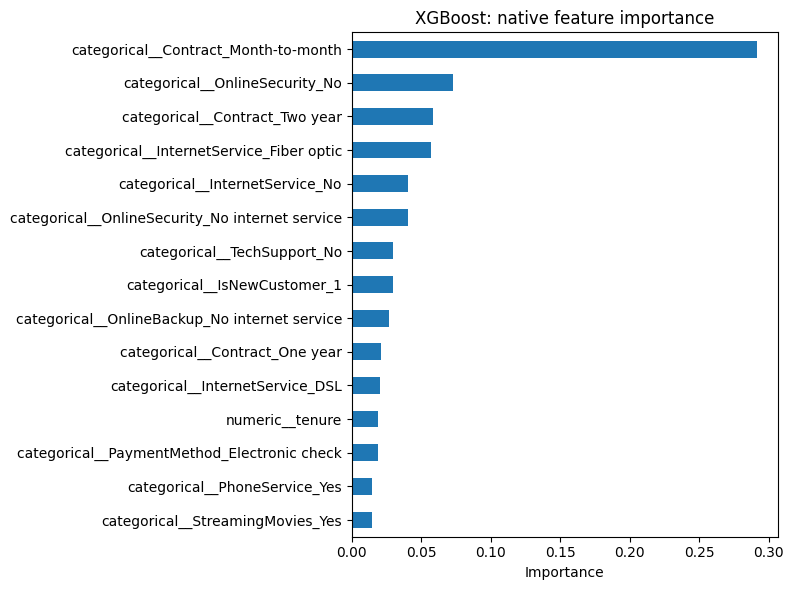

In [49]:
champion = models[best_model_name]
preprocessor = champion.named_steps["preprocessor"]
estimator = champion.named_steps["model"]

try:
    feature_names = preprocessor.get_feature_names_out()
except Exception:
    feature_names = np.array([f"feature_{i}" for i in range(len(estimator.feature_importances_))])

if hasattr(estimator, "feature_importances_"):
    native = pd.Series(
        estimator.feature_importances_,
        index=feature_names
    ).sort_values(ascending=False).head(15)

    fig, ax = plt.subplots(figsize=(8, 6))
    native.sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"{best_model_name}: native feature importance")
    ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "07_champion_feature_importance.png", dpi=250, bbox_inches="tight")
    plt.show()
else:
    print(f"{best_model_name} does not expose tree-style feature_importances_.")

### Permutation importance

Native tree importance is model-specific. Permutation importance asks a more general question:

> If we randomly shuffle this original feature, how much does test ROC-AUC fall?

A large drop means the model relies on that feature.

This is **predictive importance, not causality**.

,feature,mean_auc_drop,std_auc_drop
14,Contract,0.083479,0.007015
4,tenure,0.041301,0.004657
7,InternetService,0.011678,0.003042
18,TotalCharges,0.009852,0.002627
8,OnlineSecurity,0.003240,0.001895
16,PaymentMethod,0.002838,0.002936
17,MonthlyCharges,0.002830,0.003580
11,TechSupport,0.001865,0.001426
15,PaperlessBilling,0.001207,0.001768
9,OnlineBackup,0.000803,0.000625


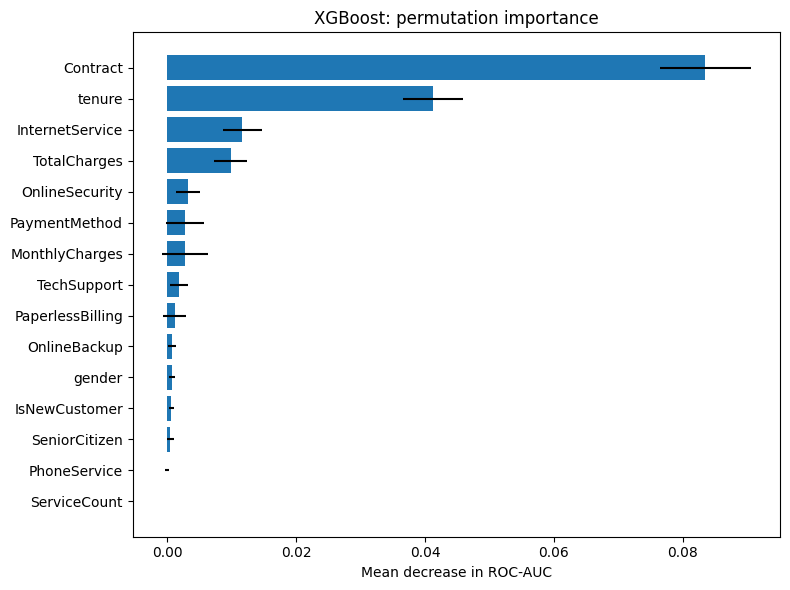

In [50]:
perm = permutation_importance(
    models[best_model_name],
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "feature": X_test.columns,
    "mean_auc_drop": perm.importances_mean,
    "std_auc_drop": perm.importances_std
}).sort_values("mean_auc_drop", ascending=False)

display(perm_df.head(15))

top = perm_df.head(15).sort_values("mean_auc_drop")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["feature"], top["mean_auc_drop"], xerr=top["std_auc_drop"])
ax.set_title(f"{best_model_name}: permutation importance")
ax.set_xlabel("Mean decrease in ROC-AUC")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_permutation_importance.png", dpi=250, bbox_inches="tight")
plt.show()

## 10. Subgroup evaluation

In [51]:
analysis = X_test.copy()
analysis["Actual_Churn"] = y_test.to_numpy()
analysis["Probability"] = test_probabilities[best_model_name].to_numpy()
analysis["Prediction"] = (analysis["Probability"] >= thresholds[best_model_name]).astype(int)
analysis["Tenure_Group"] = pd.cut(
    analysis["tenure"],
    bins=[-1, 6, 24, np.inf],
    labels=["New (<=6m)", "Growing (7-24m)", "Mature (>24m)"]
)

def subgroup_metrics(data, column):
    rows = []
    for value, group in data.groupby(column, observed=True):
        if group["Actual_Churn"].nunique() < 2:
            auc = np.nan
        else:
            auc = roc_auc_score(group["Actual_Churn"], group["Probability"])

        rows.append({
            "Group": str(value),
            "Customers": len(group),
            "Churn Rate": group["Actual_Churn"].mean(),
            "ROC-AUC": auc,
            "Precision": precision_score(group["Actual_Churn"], group["Prediction"], zero_division=0),
            "Recall": recall_score(group["Actual_Churn"], group["Prediction"], zero_division=0),
            "F1": f1_score(group["Actual_Churn"], group["Prediction"], zero_division=0)
        })
    return pd.DataFrame(rows).set_index("Group")

for col in ["Contract", "InternetService", "Tenure_Group"]:
    print(f"\n### {col}")
    display(subgroup_metrics(analysis, col).style.format({
        "Customers": "{:,}",
        "Churn Rate": "{:.1%}",
        "ROC-AUC": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}"
    }))


### Contract


,Customers,Churn Rate,ROC-AUC,Precision,Recall,F1
Group,,,,,,
Month-to-month,775,42.6%,0.746,0.550,0.852,0.668
One year,291,11.7%,0.741,0.250,0.176,0.207
Two year,339,2.4%,0.721,0.000,0.000,0.000



### InternetService


,Customers,Churn Rate,ROC-AUC,Precision,Recall,F1
Group,,,,,,
DSL,486,20.4%,0.797,0.478,0.556,0.514
Fiber optic,621,39.6%,0.811,0.561,0.898,0.691
No,298,9.1%,0.860,0.407,0.407,0.407



### Tenure_Group


,Customers,Churn Rate,ROC-AUC,Precision,Recall,F1
Group,,,,,,
New (<=6m),292,53.4%,0.757,0.617,0.910,0.736
Growing (7-24m),344,33.7%,0.754,0.524,0.750,0.617
Mature (>24m),769,13.0%,0.841,0.414,0.580,0.483


**Purpose:** check whether the overall score hides a weak subgroup.

This is diagnostic analysis, not a new tuning stage. We do not change the model after looking at the test subgroup results.

## 11. Final interpretation

In [52]:
best = results_df.loc[best_model_name]

print(f"Champion: {best_model_name}")
print(f"Test ROC-AUC: {best['ROC-AUC']:.4f}")
print(f"Test Average Precision: {best['Average Precision']:.4f}")
print(f"Test F1 at OOF-selected threshold: {best['F1']:.4f}")
print(f"Selected threshold: {best['Threshold']:.3f}")

Champion: XGBoost
Test ROC-AUC: 0.8426
Test Average Precision: 0.6554
Test F1 at OOF-selected threshold: 0.6322
Selected threshold: 0.505
